## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [4]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [5]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [6]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 2. Pembentukan Citra dan Ruang Warna
### Langkah 2.1 Lembar hitung (verifikasi dengan kode)

In [7]:
f, piksel = 4.0, 0.0014          # mm
X, Z = 5.0, 300.0                # mm
W0, H0 = 4000, 3000

def bayangan_px(Z, X=5.0):
    x_mm = f * X / Z
    return x_mm, x_mm / piksel

xa, pa = bayangan_px(300); xb, pb = bayangan_px(600)
print(f"a) Z=300 mm: x = {xa:.4f} mm = {pa:.1f} piksel")
print(f"b) Z=600 mm: x = {xb:.4f} mm = {pb:.1f} piksel  (jarak 2x, ukuran 1/2)")
Zc = f * X / (10 * piksel)
print(f"c) Z maksimum agar bercak >= 10 piksel: {Zc:.0f} mm")
skala = 640 / W0
butuh_asli = 10 / skala
Zd = f * X / (butuh_asli * piksel)
print(f"d) setelah diperkecil ke lebar 640 (skala {skala}): {pa*skala:.1f} piksel;"
      f" agar tetap >= 10 piksel perlu {butuh_asli:.1f} piksel di foto asli -> Z maks {Zd:.0f} mm")
mem = lambda w, h, c, b=8: w * h * c * b / 8
print(f"e) foto asli {mem(W0,H0,3):,.0f} B | 640x480 warna {mem(640,480,3):,.0f} B |"
      f" 640x480 abu {mem(640,480,1):,.0f} B | 300 foto asli {300*mem(W0,H0,3)/1e9:.1f} GB")
for nm, rgb in {"bercak": (196, 178, 86), "daun": (52, 136, 60)}.items():
    R, G, B = rgb
    Y = 0.299 * R + 0.587 * G + 0.114 * B
    px = np.uint8([[[B, G, R]]])
    print(f"f) {nm}: Y manual = {Y:.2f} | cv2 gray = {cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0,0]}"
          f" | Hue OpenCV = {cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0,0,0]}")

a) Z=300 mm: x = 0.0667 mm = 47.6 piksel
b) Z=600 mm: x = 0.0333 mm = 23.8 piksel  (jarak 2x, ukuran 1/2)
c) Z maksimum agar bercak >= 10 piksel: 1429 mm
d) setelah diperkecil ke lebar 640 (skala 0.16): 7.6 piksel; agar tetap >= 10 piksel perlu 62.5 piksel di foto asli -> Z maks 229 mm
e) foto asli 36,000,000 B | 640x480 warna 921,600 B | 640x480 abu 307,200 B | 300 foto asli 10.8 GB
f) bercak: Y manual = 172.89 | cv2 gray = 173 | Hue OpenCV = 25
f) daun: Y manual = 102.22 | cv2 gray = 102 | Hue OpenCV = 63


### Jawaban Lembar Hitung Bagian 2

| Butir | Penyelesaian | Jawaban |
|---|---|---|
| a | x = 4,0 x 5 / 300 = 0,0667 mm; 0,0667 / 0,0014 | **47,6 piksel** |
| b | x = 4,0 x 5 / 600 = 0,0333 mm | **23,8 piksel**; jarak 2 kali lipat, ukuran menjadi setengah (berbanding terbalik dengan Z) |
| c | 10 piksel = 0,014 mm; Z = f X / x = 20 / 0,014 | **Z maks sekitar 1.429 mm** |
| d | skala 640/4000 = 0,16; 47,6 x 0,16. Agar 10 piksel setelah diperkecil, perlu 62,5 piksel di foto asli: x = 0,0875 mm; Z = 20 / 0,0875 | **7,6 piksel** (kurang dari 10); **Z maks sekitar 229 mm** |
| e | 4000 x 3000 x 3; 640 x 480 x 3; 640 x 480 x 1; 300 x 36 MB | **36.000.000 B; 921.600 B; 307.200 B; 10,8 GB** |
| f | Y = 0,299R + 0,587G + 0,114B | **Bercak 172,89 (173); daun 102,22 (102); selisih sekitar 71.** Hue OpenCV: bercak 25 (50 derajat, kuning), daun 63 (126 derajat, hijau) |

### Langkah 2.2 Rencana akuisisi citra

In [8]:
rencana = pd.DataFrame([
 ["Jarak dan sudut", "Tegak lurus dari atas, jarak sekitar 20 cm (satu jengkal); maksimal 23 cm agar bercak 5 mm tetap >= 10 piksel setelah diperkecil ke lebar 640 px"],
 ["Resolusi minimum", "Foto asli minimal 12 MP (4000 x 3000); bila jarak lebih jauh, lebar kerja dinaikkan (misalnya 1280 px)"],
 ["Alas dan acuan ukuran", "Nampan atau kertas HVS polos berwarna terang; koin Rp500 atau penggaris di sudut bingkai untuk konversi piksel ke mm (P6)"],
 ["Kondisi cahaya", "Mewakili 5 kondisi: normal, teduh/gelap, terik, berkabut/kontras rendah, bayangan sebagian; catat kondisi setiap foto"],
 ["Jumlah citra", "Minimal 100 citra per kelas (Sehat, Ringan, Berat), seimbang antarkelas dan antarkondisi, dari minimal 3 kebun"],
 ["Penamaan berkas", "<kebun>_<kondisi>_<kelas>_<nomor>.jpg, misalnya k01_teduh_ringan_007.jpg; dicatat di catatan_akuisisi.csv"],
 ["Izin dan privasi", "Izin tertulis ketua kelompok tani; EXIF dihapus otomatis; tidak ada wajah/tangan beridentitas; foto mentah tidak diunggah ke repository publik"],
], columns=["Aspek", "Ketentuan"])
rencana.to_csv("../hasil/b2_rencana_akuisisi.csv", index=False)
display(rencana)

,Aspek,Ketentuan
0,Jarak dan sudut,"Tegak lurus dari atas, jarak sekitar 20 cm (sa..."
1,Resolusi minimum,Foto asli minimal 12 MP (4000 x 3000); bila ja...
2,Alas dan acuan ukuran,Nampan atau kertas HVS polos berwarna terang; ...
3,Kondisi cahaya,"Mewakili 5 kondisi: normal, teduh/gelap, terik..."
4,Jumlah citra,"Minimal 100 citra per kelas (Sehat, Ringan, Be..."
5,Penamaan berkas,"<kebun>_<kondisi>_<kelas>_<nomor>.jpg, misalny..."
6,Izin dan privasi,Izin tertulis ketua kelompok tani; EXIF dihapu...


### Kode 2.1 Pemisahan kanal dan Kontras Bercak

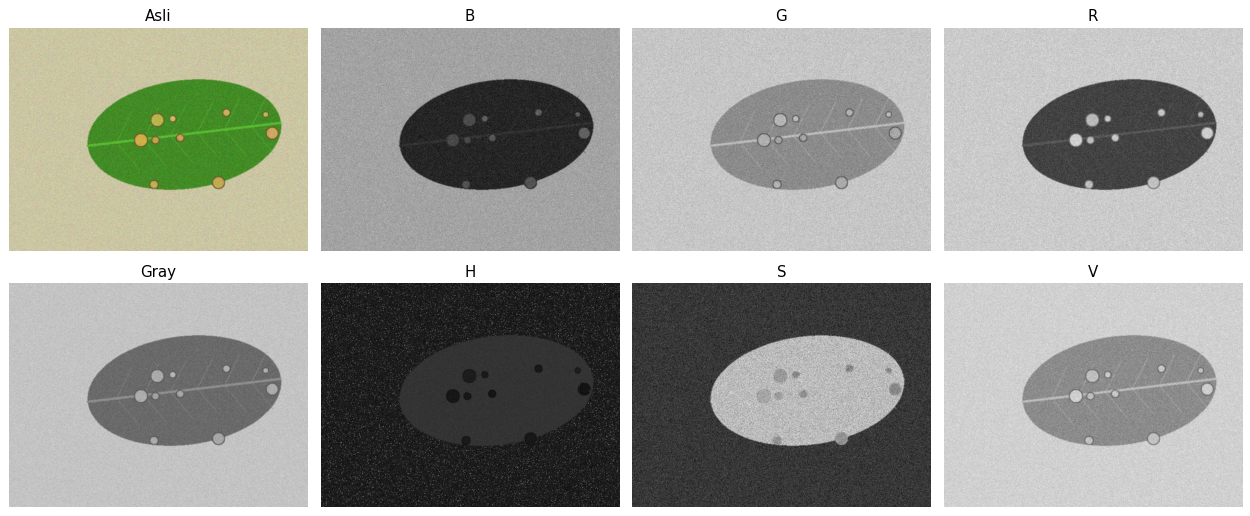

KB kanal B   : 2.24
KB kanal G   : 0.40
KB kanal R   : 7.00
KB kanal Gray: 3.44
KB kanal H   : 5.28
KB kanal S   : 1.40
KB kanal V   : 1.90


In [9]:
nama = "teh_041.png"                 # kelas berat, kondisi normal
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", bbox_inches="tight"); plt.show()
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

### Kode 2.2 Sampling dan kuantisasi

,fx,ukuran,KB
0,0.50,320x240,4.66
1,0.20,128x96,4.45
2,0.10,64x48,3.09
3,0.05,32x24,1.18


,bit,jumlah level,KB
0,1,2,3.28
1,2,3,3.32
2,3,6,2.95
3,4,11,3.18
4,8,170,3.44


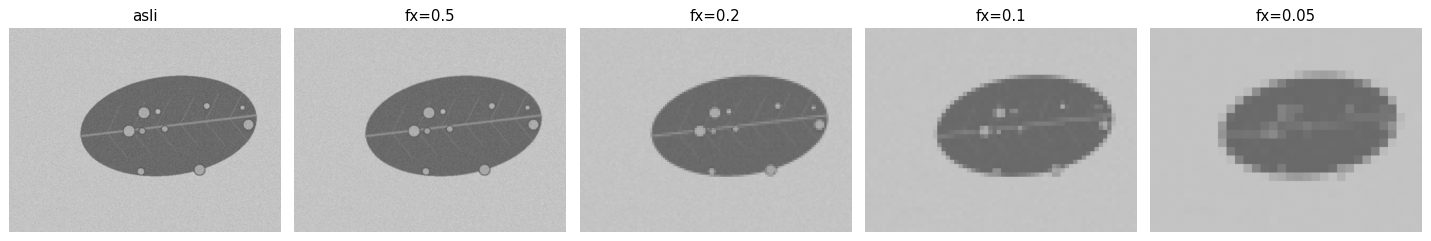

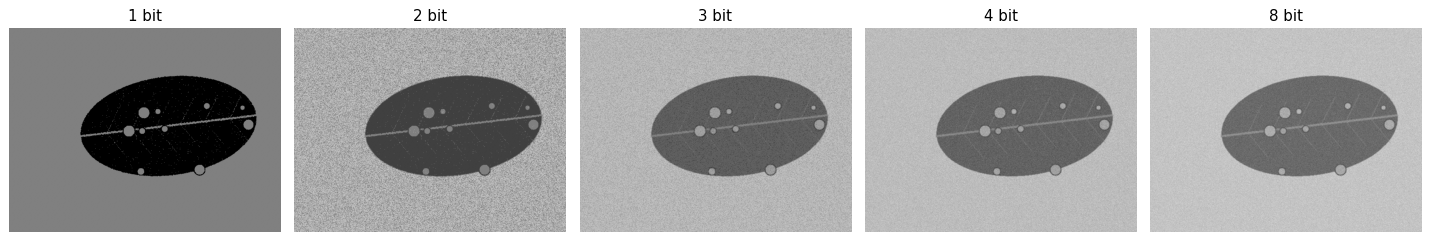

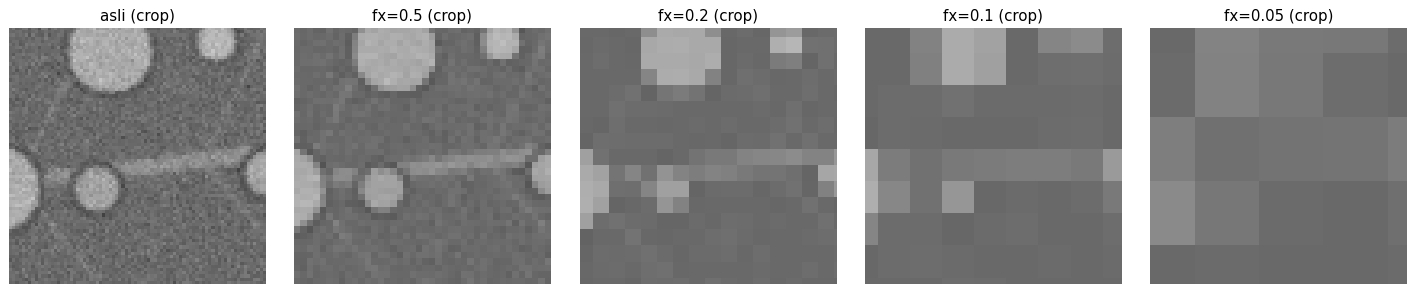

In [10]:
hasil_s, gbr_s = [], []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    hasil_s.append([fx, f"{kecil.shape[1]}x{kecil.shape[0]}", round(kontras_bercak(besar, md, mb), 2)])
    gbr_s.append(besar)
hasil_k, gbr_k = [], []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hasil_k.append([k, len(np.unique(kuant)), round(kontras_bercak(kuant, md, mb), 2)])
    gbr_k.append(kuant)
display(pd.DataFrame(hasil_s, columns=["fx", "ukuran", "KB"]))
display(pd.DataFrame(hasil_k, columns=["bit", "jumlah level", "KB"]))
tampil([gray] + gbr_s, ["asli"] + [f"fx={x[0]}" for x in hasil_s], ukuran=(16, 3.2))
plt.savefig("../hasil/b2_sampling.png", bbox_inches="tight"); plt.show()
tampil(gbr_k, [f"{x[0]} bit" for x in hasil_k], ukuran=(16, 3.2))
plt.savefig("../hasil/b2_kuantisasi.png", bbox_inches="tight"); plt.show()

# perbesar daerah bercak terbesar agar efek sampling terlihat
ys, xs = np.where(mb > 0); cy, cx = int(np.median(ys)), int(np.median(xs))
pot = lambda im: im[max(cy-40,0):cy+40, max(cx-40,0):cx+40]
tampil([pot(gray)] + [pot(x) for x in gbr_s], ["asli (crop)"] + [f"fx={x[0]} (crop)" for x in hasil_s], ukuran=(16, 3.2))
plt.show()

### Kode 2.3 Rerata KB per kanal dan per kondisi (kelas berat dan kelas ringan)

Kelas BERAT


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.29,0.54,5.40,1.80,4.98,0.63,1.24
gelap,1.29,1.57,9.40,4.68,4.83,0.76,3.46
kontras_rendah,0.67,0.23,3.66,1.87,1.93,0.24,1.16
normal,2.11,1.36,8.45,4.46,5.94,0.78,2.90
terang,1.61,0.80,6.28,3.40,4.58,0.56,1.78
RERATA,1.39,0.90,6.64,3.24,4.45,0.59,2.11


Kelas RINGAN


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,0.84,1.30,4.45,1.26,5.41,0.96,1.00
gelap,0.60,0.42,7.40,2.13,5.48,0.82,1.26
kontras_rendah,0.63,0.48,3.71,1.78,1.98,0.27,1.17
normal,1.27,0.47,7.55,3.29,5.95,0.85,1.63
terang,1.55,0.21,6.06,2.91,4.93,0.94,1.34
RERATA,0.98,0.58,5.83,2.27,4.75,0.77,1.28


Kanal dengan rerata KB tertinggi (kelas berat): R


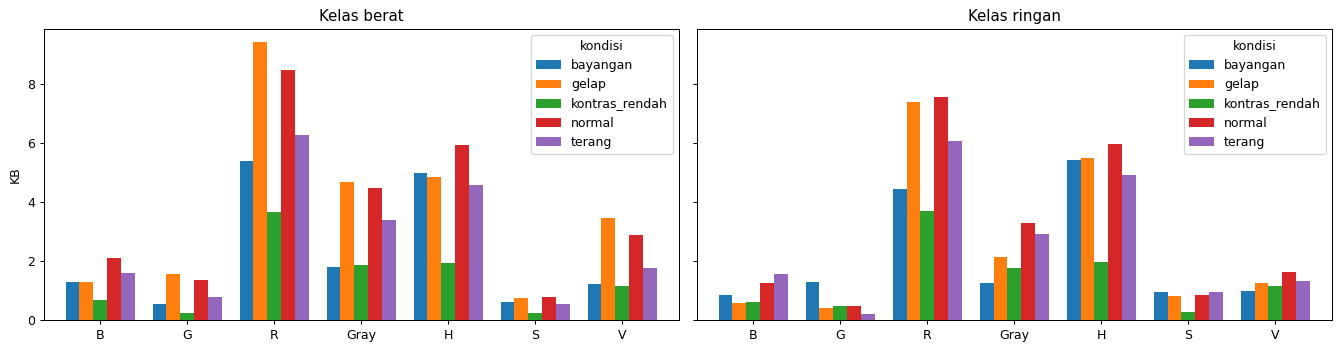

In [ ]:
def semua_kanal(im):
    hsv_ = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    b_, g_, r_ = cv2.split(im); h_, s_, v_ = cv2.split(hsv_)
    return {"B": b_, "G": g_, "R": r_, "Gray": cv2.cvtColor(im, cv2.COLOR_BGR2GRAY),
            "H": h_, "S": s_, "V": v_}

def tabel_kb_kelas(kelas):
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im, m_d, m_b = muat(d.nama_file)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    t = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
    t.loc["RERATA"] = t.mean().round(2)
    return t

tabel_kb = tabel_kb_kelas("berat");  tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")
tabel_kb_r = tabel_kb_kelas("ringan"); tabel_kb_r.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("Kelas BERAT"); display(tabel_kb)
print("Kelas RINGAN"); display(tabel_kb_r)
KANAL_TERBAIK = tabel_kb.loc["RERATA"].idxmax()
print("Kanal dengan rerata KB tertinggi (kelas berat):", KANAL_TERBAIK)

fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a, (jd, t) in zip(ax, [("Kelas berat", tabel_kb), ("Kelas ringan", tabel_kb_r)]):
    t.drop("RERATA").T.plot.bar(ax=a, rot=0, width=0.8); a.set_title(jd); a.set_ylabel("KB")
plt.tight_layout(); plt.savefig("../hasil/b2_grafik_kb.png", bbox_inches="tight"); plt.show()

### Langkah 2.6 Kanal terbaik pada teh_021 (ringan, normal) dan teh_045 (berat, bayangan)

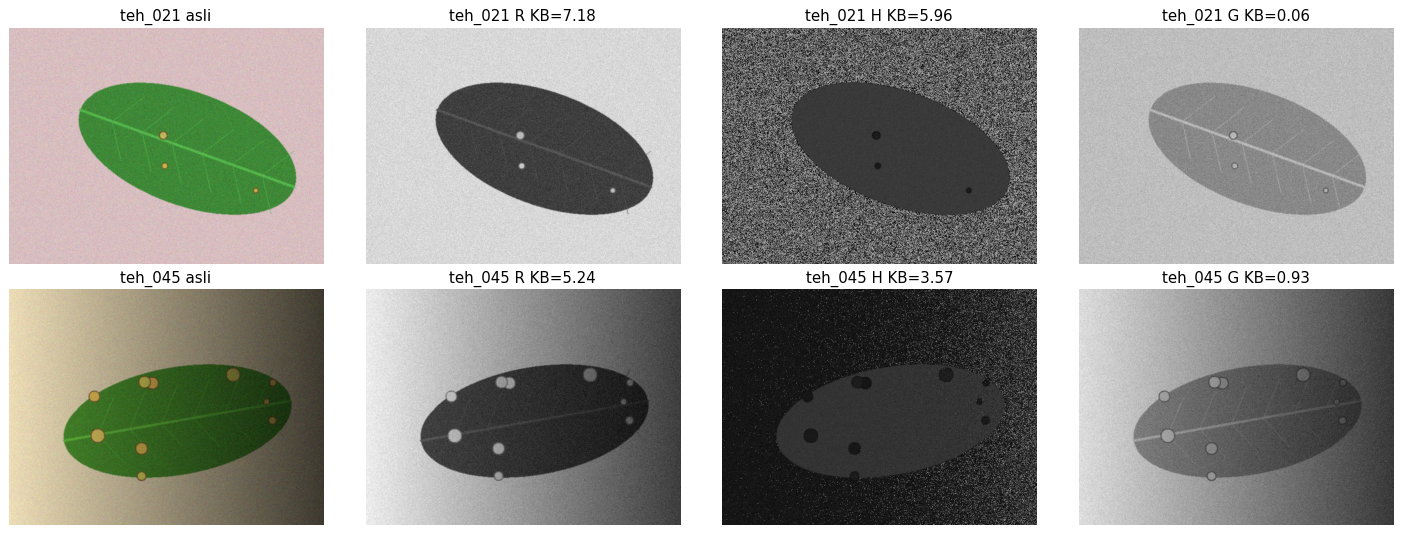

In [ ]:
daftar, judul = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im, m_d, m_b = muat(nm)
    kn = semua_kanal(im)
    daftar.append(im); judul.append(f"{nm[:7]} asli")
    for k in ["R", "H", "G"]:
        daftar.append(kn[k]); judul.append(f"{nm[:7]} {k} KB={kontras_bercak(kn[k], m_d, m_b):.2f}")
tampil(daftar, judul, baris=2, ukuran=(16, 6))
plt.savefig("../hasil/b2_panel_ringan_bayangan.png", bbox_inches="tight"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 2

**P2.1 Aturan pemotretan.** Dari butir d), bila citra kerja diperkecil ke lebar 640 piksel, bercak 5 mm hanya tetap selebar 10 piksel atau lebih bila dipotret dari jarak paling jauh sekitar 23 cm. Aturan untuk petugas: **"Potret daun tegak lurus dari atas, sejauh satu jengkal (sekitar 20 cm), dengan kamera minimal 12 MP, dan pastikan daun memenuhi sebagian besar layar."** Bila jarak 30 cm lebih nyaman, lebar kerja harus dinaikkan menjadi 1280 piksel, sehingga jarak maksimumnya menjadi sekitar 46 cm, dengan konsekuensi biaya komputasi 4 kali lipat.

**P2.2 Kanal terbaik.** Kanal **R** memberi KB tertinggi secara konsisten di semua kondisi. Untuk kelas berat, KB-nya 3,65 sampai 10,06 (rerata 7,15); untuk kelas ringan, 4,10 sampai 10,72 (rerata 6,71). Peringkat kedua adalah H, sedangkan G dan S terendah. Secara fisik, bercak cacar daun berwarna pucat kekuningan (R sekitar 196) sedangkan daun hijau memiliki komponen merah rendah (R sekitar 52), sehingga selisih di kanal R sangat besar. Di kanal G keduanya sama-sama tinggi (178 dan 136), sehingga bercak sulit dibedakan. Keabuan mencampur ketiga kanal dan mengencerkan perbedaan R, sedangkan S rendah karena bercak kuning dan daun hijau sama-sama berwarna pekat.

**P2.3 Apakah H tahan perubahan cahaya?** Sebagian besar ya. Pada kelas berat, KB H pada kondisi bayangan (5,56), gelap (5,78), dan terang (6,03) hampir sama dengan kondisi normal (6,43), sedangkan KB V anjlok menjadi 1,07, 3,19, dan 1,84. Jadi H memang memisahkan warna dari kecerahan. Namun H tidak kebal: pada kondisi kontras rendah KB H turun menjadi 1,82, karena warna menjadi pudar (saturasi rendah) dan nilai Hue menjadi tidak stabil serta peka derau. Pada data ini R tetap lebih unggul daripada H.

**P2.4 Keterbatasan KB pada kuantisasi.** Pada 1 bit KB = 5,64 dan pada 2 bit KB = 5,77, lebih tinggi daripada 8 bit (5,05). Secara visual, citra 1 bit kehilangan seluruh detail: daun menjadi hitam rata, dan tulang daun serta gradasi lenyap. KB naik bukan karena citranya lebih baik, melainkan karena kuantisasi menyeragamkan nilai daun sehingga simpangan bakunya (pembagi KB) mengecil. Hasilnya juga tidak monoton (3 bit hanya 2,99), karena bercak dan daun bisa jatuh ke tingkat yang sama atau berbeda tergantung letak batas kuantisasi. Artinya KB hanya mengukur keterpisahan bercak dari daun, bukan mutu citra secara umum, dan harus didampingi pengamatan visual serta ukuran lain.

**P2.5 Faktor sampling.** Pada fx = 0,5, KB justru naik (6,54) karena `INTER_AREA` merata-ratakan piksel dan meredam derau. Pada fx = 0,2, KB masih 5,48 dan bercak masih terlihat. Pada **fx = 0,1** (64 x 48), bercak kecil hanya tersisa 1 sampai 2 blok piksel dan mulai sulit dibedakan (KB 3,65). Pada fx = 0,05, bercak kecil hilang (KB 1,97). Diameter bercak sintetis sekitar 10 sampai 30 piksel, sehingga pada fx = 0,1 tinggal 1 sampai 3 piksel, jauh di bawah syarat 10 piksel dari butir 2.1 d).

**P2.6 Risiko EXIF.** EXIF dapat memuat koordinat GPS kebun, tanggal dan jam pemotretan, serta merek HP. Bila foto diunggah ke repository publik, lokasi kebun petani beserta data "kebun ini terserang cacar daun" dapat diketahui siapa saja. Akibatnya petani bisa dirugikan: harga ditekan pembeli, kebun distigma, atau keamanan kebun terancam. Rencana akuisisi mencegahnya dengan menghapus EXIF otomatis, menyimpan foto mentah di luar repository, memakai repository privat, dan meminta izin tertulis kelompok tani.